# CHALLENGE: AFRICAN CREDIT SCORING
## - Author: Humbulani Colbert, Nekhumbe
### - Email: nekhumbecolbert3@gmail.com
### - Mobile : 079 724 4438

# 1. Libraries

In [1]:
#Optional
# ! pip install -q -r ../requirements.txt

In [2]:
import os
import sys
import joblib
import random
import warnings
import numpy as np 
import pandas as pd 
import seaborn as sns
import networkx as nx

sys.path.append(os.path.abspath("../src"))
from helper import creditScorePipeline
import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings('ignore')
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
from catboost import CatBoostClassifier

from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OneHotEncoder, RobustScaler, OrdinalEncoder

from sklearn.model_selection import train_test_split,cross_val_score, StratifiedKFold

from lightgbm import LGBMClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer


from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score, brier_score_loss, log_loss,roc_auc_score,
    f1_score, roc_auc_score, roc_curve, precision_recall_curve, ConfusionMatrixDisplay, classification_report
)


helper_class = creditScorePipeline()

# 2. Loading the data

In [3]:
df_train = pd.read_csv("../data/Train.csv")
df_test = pd.read_csv("../data/Test.csv")
econ_raw = pd.read_csv("../data/economic_indicators.csv")

In [4]:
print(f" rain cols: {df_train.columns}")
print("Train Data")
print(df_train.info())
print(f" Test cols: {df_test.columns}")
print("\n\nTest Data")
print(df_test.info()) 
print("\n\nEconomic indicators")
print(econ_raw.info()) 

 rain cols: Index(['ID', 'customer_id', 'country_id', 'tbl_loan_id', 'lender_id',
       'loan_type', 'Total_Amount', 'Total_Amount_to_Repay',
       'disbursement_date', 'due_date', 'duration', 'New_versus_Repeat',
       'Amount_Funded_By_Lender', 'Lender_portion_Funded',
       'Lender_portion_to_be_repaid', 'target'],
      dtype='object')
Train Data
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 68654 entries, 0 to 68653
Data columns (total 16 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   ID                           68654 non-null  object 
 1   customer_id                  68654 non-null  int64  
 2   country_id                   68654 non-null  object 
 3   tbl_loan_id                  68654 non-null  int64  
 4   lender_id                    68654 non-null  int64  
 5   loan_type                    68654 non-null  object 
 6   Total_Amount                 68654 non-null  float64
 7   Total_A

In [5]:
df_train.head(10)

,ID,customer_id,country_id,tbl_loan_id,lender_id,loan_type,Total_Amount,Total_Amount_to_Repay,disbursement_date,due_date,duration,New_versus_Repeat,Amount_Funded_By_Lender,Lender_portion_Funded,Lender_portion_to_be_repaid,target
0,ID_266671248032267278,266671,Kenya,248032,267278,Type_1,8448.0,8448.0,2022-08-30,2022-09-06,7,Repeat Loan,120.85,0.014305,121.0,0
1,ID_248919228515267278,248919,Kenya,228515,267278,Type_1,25895.0,25979.0,2022-07-30,2022-08-06,7,Repeat Loan,7768.50,0.300000,7794.0,0
2,ID_308486370501251804,308486,Kenya,370501,251804,Type_7,6900.0,7142.0,2024-09-06,2024-09-13,7,Repeat Loan,1380.00,0.200000,1428.0,0
3,ID_266004285009267278,266004,Kenya,285009,267278,Type_1,8958.0,9233.0,2022-10-20,2022-10-27,7,Repeat Loan,2687.40,0.300000,2770.0,0
4,ID_253803305312267278,253803,Kenya,305312,267278,Type_1,4564.0,4728.0,2022-11-28,2022-12-05,7,Repeat Loan,1369.20,0.300000,1418.0,0
5,ID_265607284433267278,265607,Kenya,284433,267278,Type_1,4325.0,4325.0,2022-10-19,2022-10-26,7,Repeat Loan,1297.50,0.300000,1298.0,0
6,ID_261844305920267278,261844,Kenya,305920,267278,Type_1,6735.0,6735.0,2022-11-29,2022-12-06,7,Repeat Loan,2020.50,0.300000,2021.0,0
7,ID_265488287698267278,265488,Kenya,287698,267278,Type_1,1540.0,1562.0,2022-10-25,2022-11-01,7,Repeat Loan,462.00,0.300000,469.0,0
8,ID_268010279432267278,268010,Kenya,279432,267278,Type_1,21496.0,21994.0,2022-10-11,2022-10-18,7,Repeat Loan,0.00,0.000000,0.0,0
9,ID_245399236898267278,245399,Kenya,236898,267278,Type_1,18852.0,18852.0,2022-08-15,2022-08-22,7,Repeat Loan,5655.60,0.300000,5656.0,0


In [6]:
econ_raw.head(4)

,Country,Indicator,YR2001,YR2002,YR2003,YR2004,YR2005,YR2006,YR2007,YR2008,YR2009,YR2010,YR2011,YR2012,YR2013,YR2014,YR2015,YR2016,YR2017,YR2018,YR2019,YR2020,YR2021,YR2022,YR2023
0,Ghana,"Inflation, consumer prices (annual %)",41.509496,9.360932,29.772980,18.042739,15.438992,11.679184,10.734267,16.494640,19.246948,10.733390,8.728459,11.186341,11.666192,15.489616,17.149970,17.454635,12.371922,7.808765,7.143640,9.887290,9.971089,31.255895,38.106966
1,Cote d'Ivoire,"Inflation, consumer prices (annual %)",4.361529,3.077265,3.296807,1.457988,3.885830,2.467191,1.892006,6.308528,1.019505,1.226456,4.912434,1.304511,2.581170,0.448682,1.251500,0.723178,0.685881,0.359409,-1.106863,2.425007,4.091952,5.276167,4.387117
2,Kenya,"Inflation, consumer prices (annual %)",5.738598,1.961308,9.815691,11.624036,10.312778,14.453734,9.758880,26.239817,9.234126,3.961389,14.022491,9.377770,5.717494,6.878155,6.582154,6.297250,8.005650,4.689806,5.239638,5.405162,6.107936,7.659863,7.671396
3,Ghana,"Official exchange rate (LCU per US$, period av...",0.716305,0.792417,0.866764,0.899495,0.905209,0.915107,0.932619,1.052275,1.404967,1.429983,1.520625,1.824867,1.981350,2.896575,3.714642,3.909817,4.350533,4.585325,5.217367,5.595708,5.805700,8.272400,11.020408


## Statistical summary

In [7]:
from summarytools import dfSummary
dfSummary(df_train)

No,Variable,Stats / Values,Freqs / (% of Valid),Graph,Missing
1,ID[object],1. ID_2666712480322672782. ID_2695752625872672783. ID_2654992484232672784. ID_2856063574202672785. ID_2588882983512672786. ID_2525782779242672787. ID_2540812409712672788. ID_897032603172672789. ID_25778122787226727810. ID_23807126160526727811. other,"1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)1 (0.0%)68,644 (100.0%)","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAJsAAAD+CAYAAAAtWHdlAAAAOXRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjkuMiwgaHR0cHM6Ly9tYXRwbG90bGliLm9yZy8hTgPZAAAACXBIWXMAAA9hAAAPYQGoP6dpAAADLklEQVR4nO3cwY3TYBRG0ecogmFja2QpJUAPKYItvdOFNzCswoIeriVzTgX/4kpPkfxleb1eA4Xb2Q/g/yE2MmIjIzYyYiMjNjJiIyM2MmIjIzYyt2VZvi3L8nb2Q7i+28x8nZnPZz+E63NGyYiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI3MbWZ+zsyfsx/C9S3+xYiKM0pGbGSsq8hYV5FxRsmIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyBi8kDF4IeOMkhEbGYMXMgYvZJxRMmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyBi9kDF7IOKNkxEZGbGSsq8hYV5FxRsmIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyFhXkbGuIuOMkhEbGYMXMgYvZJxRMmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyBi9kDF7IOKNkxEbG4IWMwQsZZ5SM2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzYyFhXkbGuIuOMkhEbGesqMtZVZJxRMmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYyBi9kDF7IOKNkxEbG4IWMwQsZZ5SM2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzBCxmDFzLOKBmxkREbGesqMtZVZJxRMmIjIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjIzYy1lVkrKvIOKNkxEbG4IWMwQsZZ5SM2MiIjYzYyIiNjNjIiI2M2MiIjYzYyIiNjNjIiI2M2MiIjYzBCxmDFzLOKJllZr7MzKezH8L13fd9/76u6/vZD+H67uu6vj+fz9/btn2c/Riu6ziOt/vMzLZtH4/H49fZD+La/EAgIzYyYiMjNjJiIyM2MmIjIzYyYiMjNjJiIyM2MmIjc5/59/nH2Q/h2o7jeFv2ff/h40kKPgsnY11Fxg8EMmIjIzYyYiMjNjJiIyM2MmIjIzYyfwFj50uCzHpkKgAAAABJRU5ErkJggg=="">",0(0.0%)
2,customer_id[int64],Mean (sd) : 254390.3 (26642.7)min < med < max:145.0 < 255361.0 < 312737.0IQR (CV) : 13323.5 (9.5),"6,540 distinct values","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAKoAAABGCAYAAABc8A97AAAAOXRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjkuMiwgaHR0cHM6Ly9tYXRwbG90bGliLm9yZy8hTgPZAAAACXBIWXMAAA9hAAAPYQGoP6dpAAACG0lEQVR4nO3dwW6iUBSH8XMHtVQTiDHRnS8wSRcufYh52D7CLHgC38CdCSEQGQkIdDEzSTedKQht/+b7bc3Bs/g2LLjXtW1rwFf37bMXAN5j8tkL4Otwzj2a2eyGR5Rt216G2uc1QoWZ/Y50tVr9CIJg2fcZWZYlzrnnMWIlVPw1C4Jgud/vL2EYFl2H0zT1oyhaxnE8MzNCxbjCMCzW6/WvnuOPgy7zCi9TkECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokECokMDR6HfmhptNgqZppkPvMxRCvSO33GxSVZVf1/X3oih+mlnfM/xHQ6j3pffNJsfjcXk4HObX69Uba7lbEOod6nOzSZIko91oMgRepiCBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBUCGBr1AxmLqup2YWOOf6jJdt217e+pFQMYg8z6dVVT1tt1vP87xOZwqYmWVZljjnnt+KlVAxiLIsJ77vz3e7XbHZbJIus2ma+lEULeM4npkZoWJ8i8Wi8+EXf/zzAIz/huqc883soccf4+MFTdNM0jT1uw6ez2ffzCzPc/90Os0/cv49+74ADxSCZTNjFjMAAAAASUVORK5CYII="">",0(0.0%)
3,country_id[object],1. Kenya,"68,654 (100.0%)",,0(0.0%)
4,tbl_loan_id[int64],Mean (sd) : 263056.3 (39486.7)min < med < max:101323.0 < 260305.5 < 375320.0IQR (CV) : 53020.5 (6.7),"66,520 distinct values","<img src = ""data:image/png;base64, iVBORw0KGgoAAAANSUhEUgAAAKoAAABGCAYAAABc8A97AAAAOXRFWHRTb2Z0d2FyZQBNYXRwbG90bGliIHZlcnNpb24zLjkuMiwgaHR0cHM6Ly9tYXRwbG90bGliLm9yZy8hTgPZAAAACXBIWXMAAA9hAAAPYQGoP6dpAAACqUlEQVR4nO3cvW7aYBSA4XP4k53Qz0IgsnnpWImBkSV3kIvtmjESSN24gO4IBWEj3FAsmw7N0CFKsDHBh77PfsDDK8v8fEcPh4MAdde49AUAx2hd+gLqSlV9EemUHN8fDoeXKq/nf0eob1BVv9/vPzjnemXmN5vNWlW/E2t1CPVtHedcbzKZvARBsCsyGMex9/T0NFytVgNV3ZR4b+7GbyDUdwRBsBsOh7+KzCRJ0k7TdBSGYbPZbBaKXEQkiqKtqj6KSOHZV1cZOqFWbL/ftzzPuxmPx7u7u7t1kdnFYvFlNpvdh2E4KBO5yPU+dhDqmdze3ha+G6/Xa79s5CJ/Hzum02lvtVp1RIRQcV5lIv+HX+nF1ATfo8IEQoUJhAoTCBUmECpMIFSYQKgwgVBhAqHCBEKFCYQKEwgVJhAqTCBUmECoMIFQYQKhwgRChQmEChMIFSYQKkwgVJhAqDCBUGECocIEQoUJrPS5MlmWtUXEqWqZ8dpuAiTUK3Lqyss6bwIk1CtyysrLum8CJNQrdMI2wNpuAuTDFEwgVJhAqDCBUGECocIEQoUJhAoTCBUmECpMIFSYQKgwgVBhAqHCBEKFCYQKEwgVJhAqTOAf/qiMqvoi0ik5/u7BQkJFJVTV7/f7D865Xpn5jw4WEiqq0nHO9SaTyUsQBIVOwB5zsJBQUakgCM5ysJAPUzCBUGECocIEQoUJhAoTCBUmECpM+

- Country is less important since this is all from one country (Kenya)
- Date columns can also be represented by feature engineered before EDA to explore engineered features as well on EDA. 
- The rest of the columsn to be explored with EDA below

# 3. Exploratory Data Analysis
Understanding our data

## 3.1  Feature Engineering date features

In [8]:
df_train.shape

(68654, 16)

In [9]:
# Apply to both training and test set
df_train = helper_class.feature_engineering_dates(df_train)
df_test = helper_class.feature_engineering_dates(df_test)

**join economic indicators based on year and a country of a customer just to understand the economic behaviour during the loan period**

In [10]:
print(f"Train unique disbursement_year {df_train['due_year'].unique()}")
print(f"unique disbursement_year  {df_test['disbursement_year'].unique()}")

print(f"Train unique country {df_train['country_id'].unique()}")
print(f"unique country  {df_test['country_id'].unique()}")

Train unique disbursement_year [2022 2024 2023 2025 2021]
unique disbursement_year  [2022 2024 2023 2021]
Train unique country ['Kenya']
unique country  ['Kenya' 'Ghana']


In [11]:
econ_raw.isnull().sum()

Country       0
Indicator     0
YR2001        7
YR2002        7
YR2003        7
YR2004        7
YR2005        3
YR2006        3
YR2007        3
YR2008        3
YR2009        3
YR2010        3
YR2011        3
YR2012        3
YR2013        3
YR2014        3
YR2015        6
YR2016        6
YR2017        6
YR2018       10
YR2019       10
YR2020       10
YR2021       10
YR2022       13
YR2023       13
dtype: int64

In [12]:
# Melt 
econ_long = econ_raw.melt(
    id_vars=["Country", "Indicator"],
    var_name="year",
    value_name="value"
)

# Clean up year column
econ_long['year'] = econ_long['year'].str.extract(r'(\d{4})').astype(int)

# Pivot 
econ_pivot = econ_long.pivot_table(index=['Country', 'year'], 
                                   columns='Indicator', 
                                   values='value').reset_index()

# Impute missing values by country group using median to avoid using indicator for the other country on another country
for col in econ_pivot.columns[2:]:  
    # First try filling by country median
    econ_pivot[col] = econ_pivot.groupby('Country')[col].transform(lambda grp: grp.fillna(grp.median()))
    
    # Then fill any remaining missing values with global median
    econ_pivot[col] = econ_pivot[col].fillna(econ_pivot[col].median())

In [13]:
econ_pivot.columns

Index(['Country', 'year', 'Average precipitation in depth (mm per year)',
       'Deposit interest rate (%)',
       'Fossil fuel energy consumption (% of total)',
       'Inflation, consumer prices (annual %)',
       'Interest rate spread (lending rate minus deposit rate, %)',
       'Lending interest rate (%)',
       'Official exchange rate (LCU per US$, period average)',
       'Real interest rate (%)', 'Unemployment rate'],
      dtype='object', name='Indicator')

In [14]:
econ_pivot.isnull().sum()

Indicator
Country                                                      0
year                                                         0
Average precipitation in depth (mm per year)                 0
Deposit interest rate (%)                                    0
Fossil fuel energy consumption (% of total)                  0
Inflation, consumer prices (annual %)                        0
Interest rate spread (lending rate minus deposit rate, %)    0
Lending interest rate (%)                                    0
Official exchange rate (LCU per US$, period average)         0
Real interest rate (%)                                       0
Unemployment rate                                            0
dtype: int64

In [15]:
econ_pivot.head()

Indicator,Country,year,Average precipitation in depth (mm per year),Deposit interest rate (%),Fossil fuel energy consumption (% of total),"Inflation, consumer prices (annual %)","Interest rate spread (lending rate minus deposit rate, %)",Lending interest rate (%),"Official exchange rate (LCU per US$, period average)",Real interest rate (%),Unemployment rate
0,Cote d'Ivoire,2001,1348.0,7.813333,34.298397,4.361529,-2.953333,5.140000,732.397693,3.331831,5.199
1,Cote d'Ivoire,2002,1348.0,7.813333,37.848716,3.077265,-2.953333,5.140000,693.713226,3.331831,5.516
2,Cote d'Ivoire,2003,1348.0,7.813333,32.501441,3.296807,-2.953333,5.140000,579.897426,3.331831,5.858
3,Cote d'Ivoire,2004,1348.0,7.813333,24.930573,1.457988,-2.953333,5.140000,527.338032,3.331831,5.930
4,Cote d'Ivoire,2005,1348.0,7.607500,25.391257,3.885830,-0.558333,7.049167,527.258363,5.763991,6.041


In [16]:
# Left join: keep all df_train rows
df_train = df_train.merge(
    econ_pivot,
    how='left',
    left_on=['country_id', 'disbursement_year'],
    right_on=['Country', 'year']
)

# Left join: keep all df_test rows
df_test = df_test.merge(
    econ_pivot,
    how='left',
    left_on=['country_id', 'disbursement_year'],
    right_on=['Country', 'year']
)


df_train.drop(columns=['Country', 'year'], inplace=True)
df_test.drop(columns=['Country', 'year'], inplace=True)

In [17]:
df_train.shape

(68654, 29)

In [18]:
df_train.columns

Index(['ID', 'customer_id', 'country_id', 'tbl_loan_id', 'lender_id',
       'loan_type', 'Total_Amount', 'Total_Amount_to_Repay', 'duration',
       'New_versus_Repeat', 'Amount_Funded_By_Lender', 'Lender_portion_Funded',
       'Lender_portion_to_be_repaid', 'target', 'disbursement_year',
       'disbursement_month', 'disbursement_dayofweek', 'due_year', 'due_month',
       'due_dayofweek', 'Average precipitation in depth (mm per year)',
       'Deposit interest rate (%)',
       'Fossil fuel energy consumption (% of total)',
       'Inflation, consumer prices (annual %)',
       'Interest rate spread (lending rate minus deposit rate, %)',
       'Lending interest rate (%)',
       'Official exchange rate (LCU per US$, period average)',
       'Real interest rate (%)', 'Unemployment rate'],
      dtype='object')

In [19]:
df_test.columns

Index(['ID', 'customer_id', 'country_id', 'tbl_loan_id', 'lender_id',
       'loan_type', 'Total_Amount', 'Total_Amount_to_Repay', 'duration',
       'New_versus_Repeat', 'Amount_Funded_By_Lender', 'Lender_portion_Funded',
       'Lender_portion_to_be_repaid', 'disbursement_year',
       'disbursement_month', 'disbursement_dayofweek', 'due_year', 'due_month',
       'due_dayofweek', 'Average precipitation in depth (mm per year)',
       'Deposit interest rate (%)',
       'Fossil fuel energy consumption (% of total)',
       'Inflation, consumer prices (annual %)',
       'Interest rate spread (lending rate minus deposit rate, %)',
       'Lending interest rate (%)',
       'Official exchange rate (LCU per US$, period average)',
       'Real interest rate (%)', 'Unemployment rate'],
      dtype='object')

In [20]:
df_train.dtypes

ID                                                            object
customer_id                                                    int64
country_id                                                    object
tbl_loan_id                                                    int64
lender_id                                                      int64
loan_type                                                     object
Total_Amount                                                 float64
Total_Amount_to_Repay                                        float64
duration                                                       int64
New_versus_Repeat                                             object
Amount_Funded_By_Lender                                      float64
Lender_portion_Funded                                        float64
Lender_portion_to_be_repaid                                  float64
target                                                         int64
disbursement_year                 

## 3.2 Missing values on the data

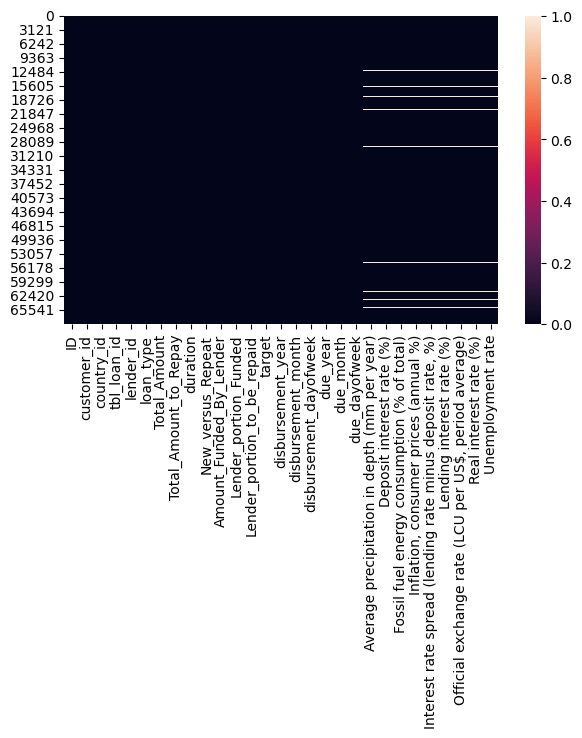

In [21]:
plt.rcParams['figure.figsize'] = (7, 4)
sns.heatmap(df_train.isnull())
plt.show()

In [22]:
df_train.isnull().sum()

ID                                                              0
customer_id                                                     0
country_id                                                      0
tbl_loan_id                                                     0
lender_id                                                       0
loan_type                                                       0
Total_Amount                                                    0
Total_Amount_to_Repay                                           0
duration                                                        0
New_versus_Repeat                                               0
Amount_Funded_By_Lender                                         0
Lender_portion_Funded                                           0
Lender_portion_to_be_repaid                                     0
target                                                          0
disbursement_year                                               0
disburseme

In [23]:
2970/df_train.shape[0]*100

4.326040725959158

- above shows that they're missing values on the economic indicators and this is because we dont have year 2024 on the indicators. 
- sicne the missing values is less than 10%, im happy to use median inputation to replace the missign values 

In [24]:
econ_cols = [
    'Average precipitation in depth (mm per year)',
    'Deposit interest rate (%)',
    'Fossil fuel energy consumption (% of total)',
    'Inflation, consumer prices (annual %)',
    'Interest rate spread (lending rate minus deposit rate, %)',
    'Lending interest rate (%)',
    'Official exchange rate (LCU per US$, period average)',
    'Real interest rate (%)',
    'Unemployment rate'
]

# Impute missing values 
for col in econ_cols:
    df_train[col] = df_train.groupby('country_id')[col].transform(
        lambda grp: grp.fillna(grp.median())
    )

    df_test[col] = df_test.groupby('country_id')[col].transform(
        lambda grp: grp.fillna(grp.median()))

for col in econ_cols:
    df_train[col].fillna(df_train[col].median(), inplace=True)
    df_test[col].fillna(df_test[col].median(), inplace=True)


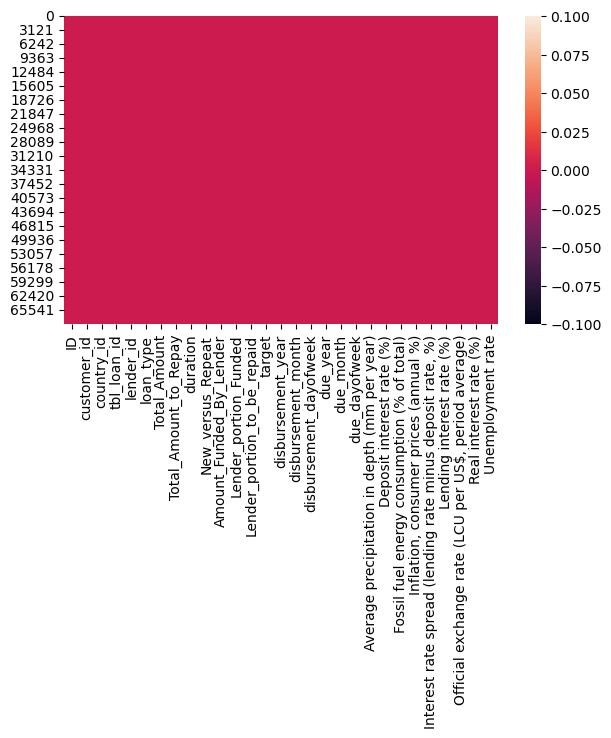

In [25]:
plt.rcParams['figure.figsize'] = (7, 4)
sns.heatmap(df_train.isnull())
plt.show()

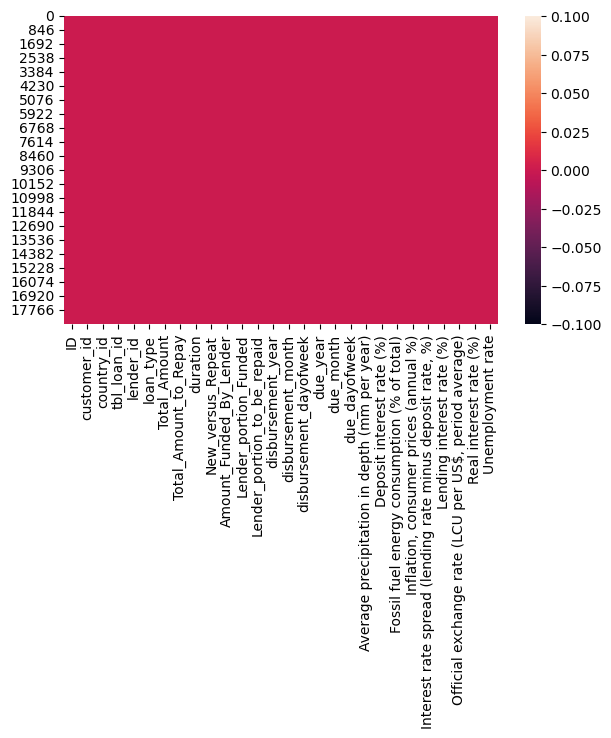

In [26]:
plt.rcParams['figure.figsize'] = (7, 4)
sns.heatmap(df_test.isnull())
plt.show()

**The heatmaps indicate missing values in a column using dashes. The heatmap above is clear, with no dashes which suggests that there are no missing values. This is further confirmed by the null check shown below the plot, which indicates zero null values in our dataset. The above confirms that there are no missing data points in our data.**

## 3.3 Duplicates
It's highly importaant to Check for number of duplicate rows in our data just for the data quality

In [27]:
print(f"TRain set Shape before removing duplicates: {df_train.shape}")
print(f"Test set shape before removing duplicates: {df_test.shape}")
train_num_duplicates = df_train.duplicated().sum()
test_num_duplicates = df_test.duplicated().sum()
print(f"Number of duplicate rows on train are {train_num_duplicates} and on test are {test_num_duplicates}")
df_train = df_train.drop_duplicates()
df_test = df_test.drop_duplicates()
print(f"Shape of train set after removing duplicates: {df_train.shape}")
print(f"Shape of test set after removing duplicates: {df_test.shape}")

TRain set Shape before removing duplicates: (68654, 29)
Test set shape before removing duplicates: (18594, 28)
Number of duplicate rows on train are 0 and on test are 0
Shape of train set after removing duplicates: (68654, 29)
Shape of test set after removing duplicates: (18594, 28)


In [28]:
df_train.columns

Index(['ID', 'customer_id', 'country_id', 'tbl_loan_id', 'lender_id',
       'loan_type', 'Total_Amount', 'Total_Amount_to_Repay', 'duration',
       'New_versus_Repeat', 'Amount_Funded_By_Lender', 'Lender_portion_Funded',
       'Lender_portion_to_be_repaid', 'target', 'disbursement_year',
       'disbursement_month', 'disbursement_dayofweek', 'due_year', 'due_month',
       'due_dayofweek', 'Average precipitation in depth (mm per year)',
       'Deposit interest rate (%)',
       'Fossil fuel energy consumption (% of total)',
       'Inflation, consumer prices (annual %)',
       'Interest rate spread (lending rate minus deposit rate, %)',
       'Lending interest rate (%)',
       'Official exchange rate (LCU per US$, period average)',
       'Real interest rate (%)', 'Unemployment rate'],
      dtype='object')

In [29]:
# Remove Noise columns
# keep ids for the purpose of mapping the reults to the ids
df_ids_train = df_train[helper_class.Id_cols]
df_ids_test = df_test[helper_class.Id_cols]
df_train.drop(columns = helper_class.Id_cols, inplace = True)
df_test.drop(columns = helper_class.Id_cols, inplace = True)

**Above shows that our data have zero duplicates**

## 3.4. Data Distribution

### 3.4.1 Histgrams plot

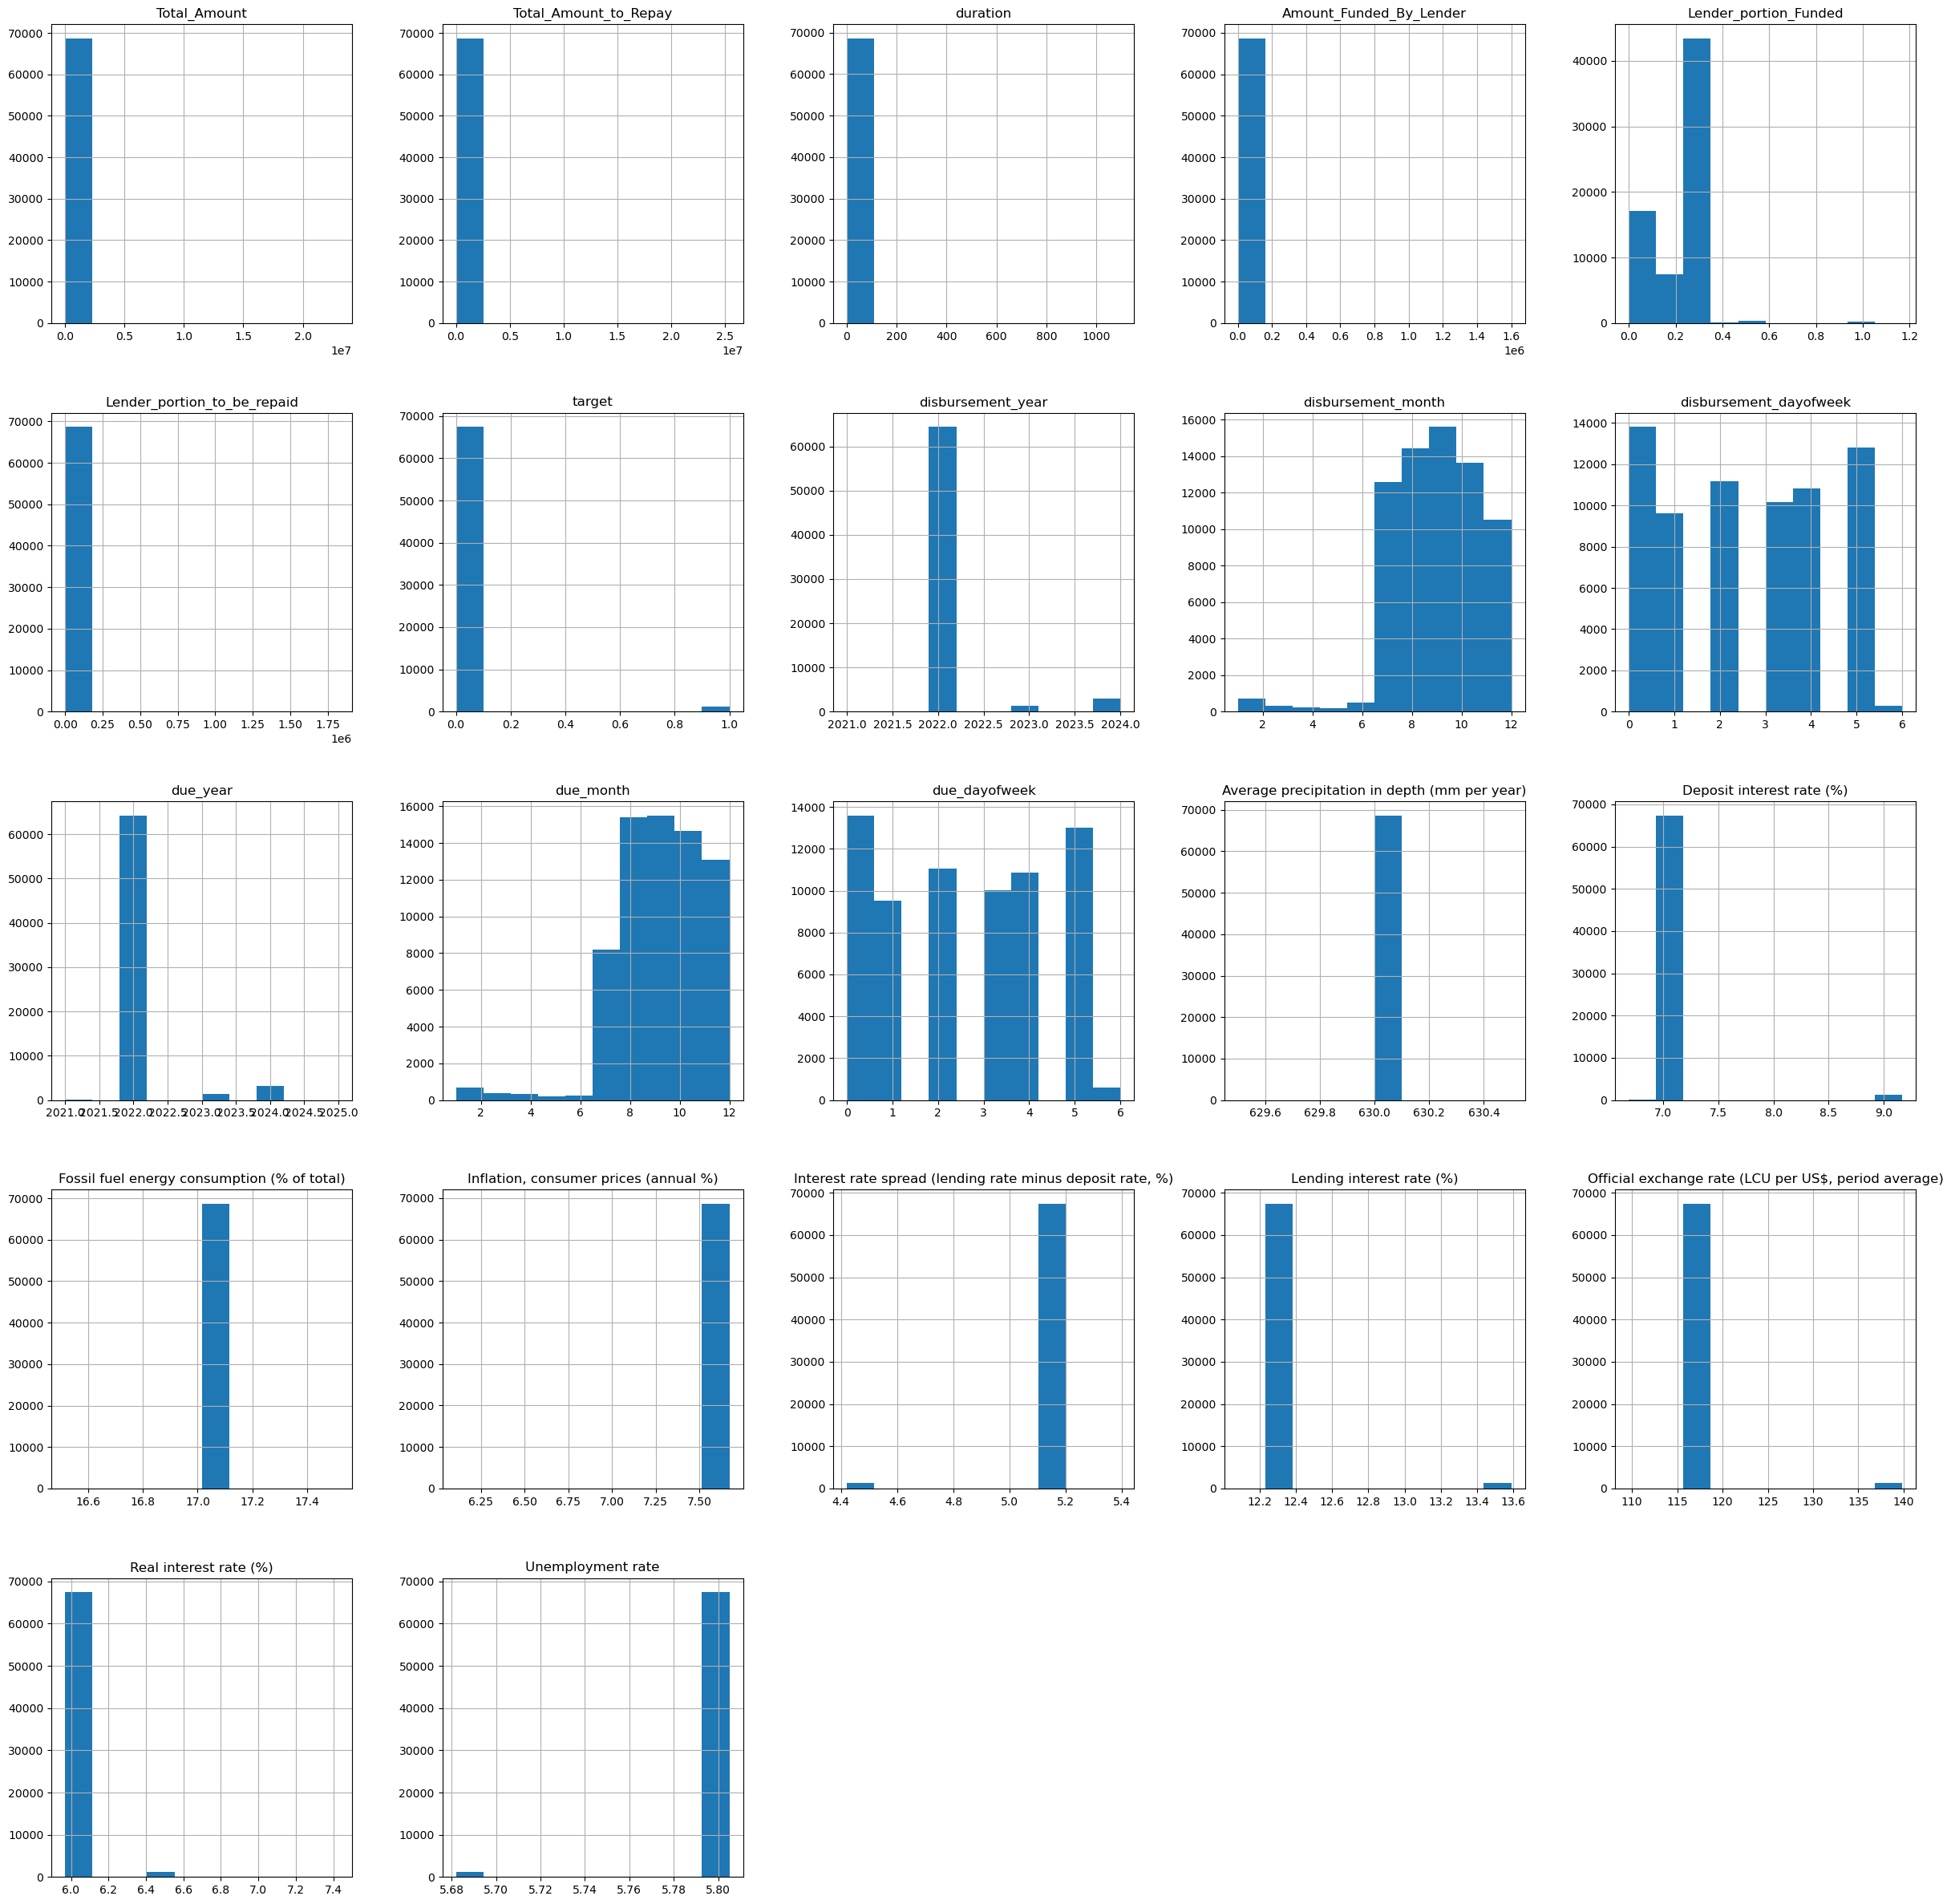

In [30]:
df_train.hist(figsize=(30,30))
plt.show()

**above shows that some of our features are skewed and not normally distributed. This suggests that before modeling, we may need to scale the data to ensure all features are on a similar scale. It also highlights the importance of identifying and evaluating the presence of outliers in our dataset.**

## 3.5 Categorical features

### 3.5.1 Loan type

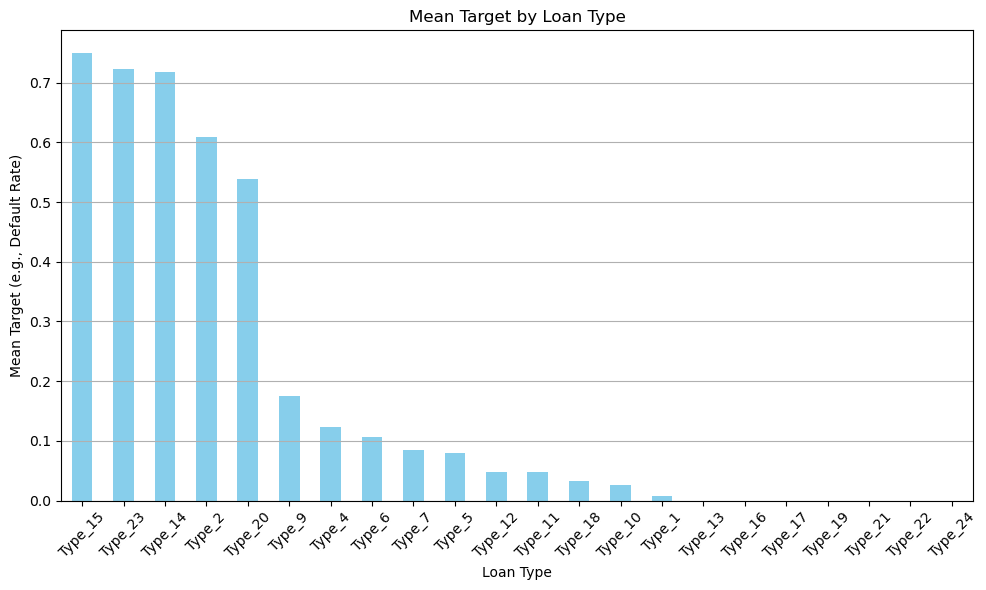

In [31]:
agg_df = df_train.groupby('loan_type')['target'].agg(['count', 'mean']).sort_values(by='mean', ascending=False)
plt.figure(figsize=(10, 6))
agg_df['mean'].plot(kind='bar', color='skyblue')
plt.title('Mean Target by Loan Type')
plt.ylabel('Mean Target (e.g., Default Rate)')
plt.xlabel('Loan Type')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**Some loan types (e.g., Type_15, Type_23, Type_14) have very high default rates (~70%+), while others (e.g., Type_24, Type_22, Type_1) have almost zero. This tells us:**
- loan_type is not ordinal (values aren't sorted in increasing risk.
- It has strong predictive power and should kept in for modelling

### 3.5.2 New_versus_Repeat

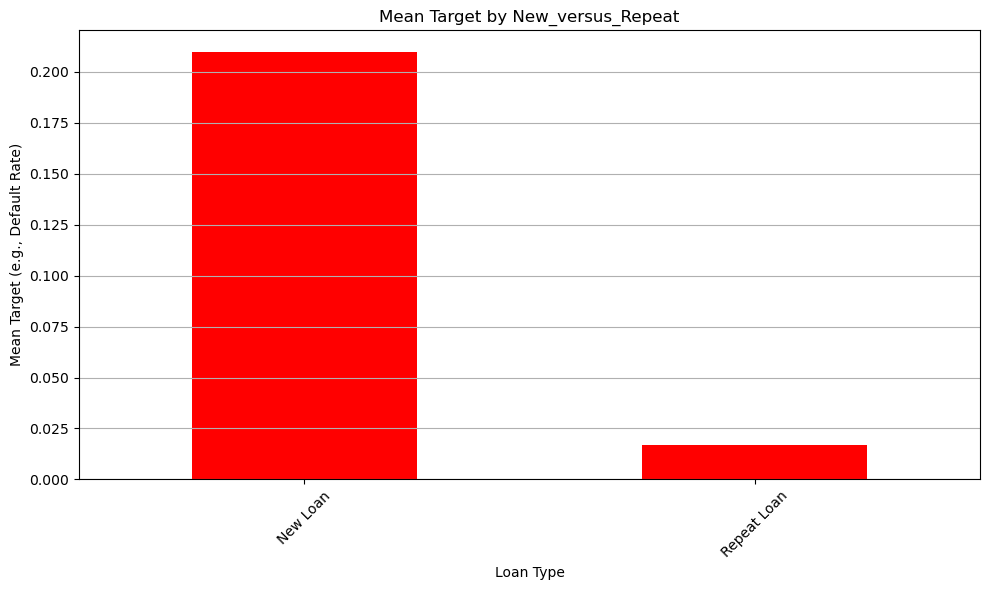

In [32]:
agg_df = df_train.groupby('New_versus_Repeat')['target'].agg(['count', 'mean']).sort_values(by='mean', ascending=False)
plt.figure(figsize=(10, 6))
agg_df['mean'].plot(kind='bar', color='red')
plt.title('Mean Target by New_versus_Repeat')
plt.ylabel('Mean Target (e.g., Default Rate)')
plt.xlabel('Loan Type')
plt.xticks(rotation=45)
plt.grid(axis='y')
plt.tight_layout()
plt.show()

**above shows imbalance between new loan customers vs the repeat customers**

### 5.5.3 Target

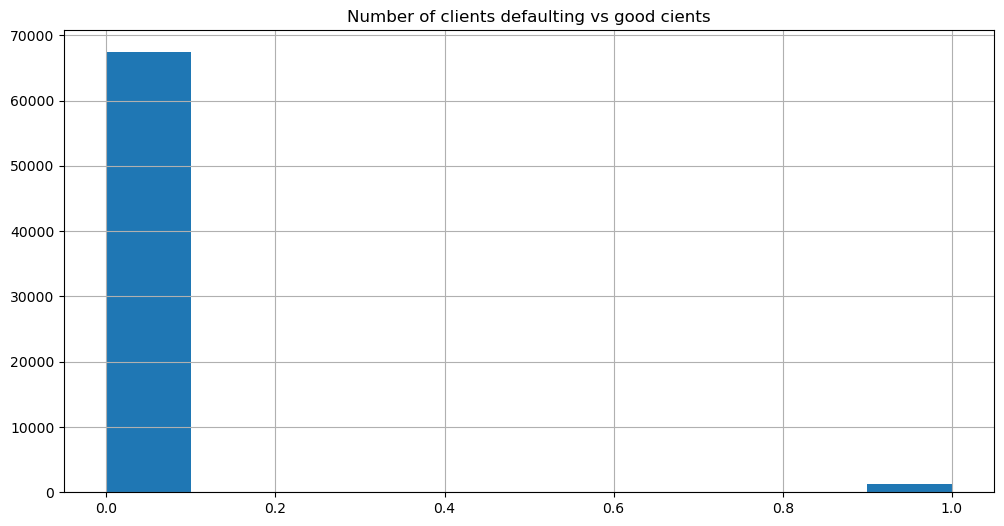

In [33]:
plt.figure(figsize = (12,12))
df_train['target'].hist(figsize=(12,6))
plt.title("Number of clients defaulting vs good cients")
plt.show()

**Above shows a imbalance between the defaulting customers and the customers that paid their loan.**

## 3.4 Correlation Matrix
Understanding relationship between our features

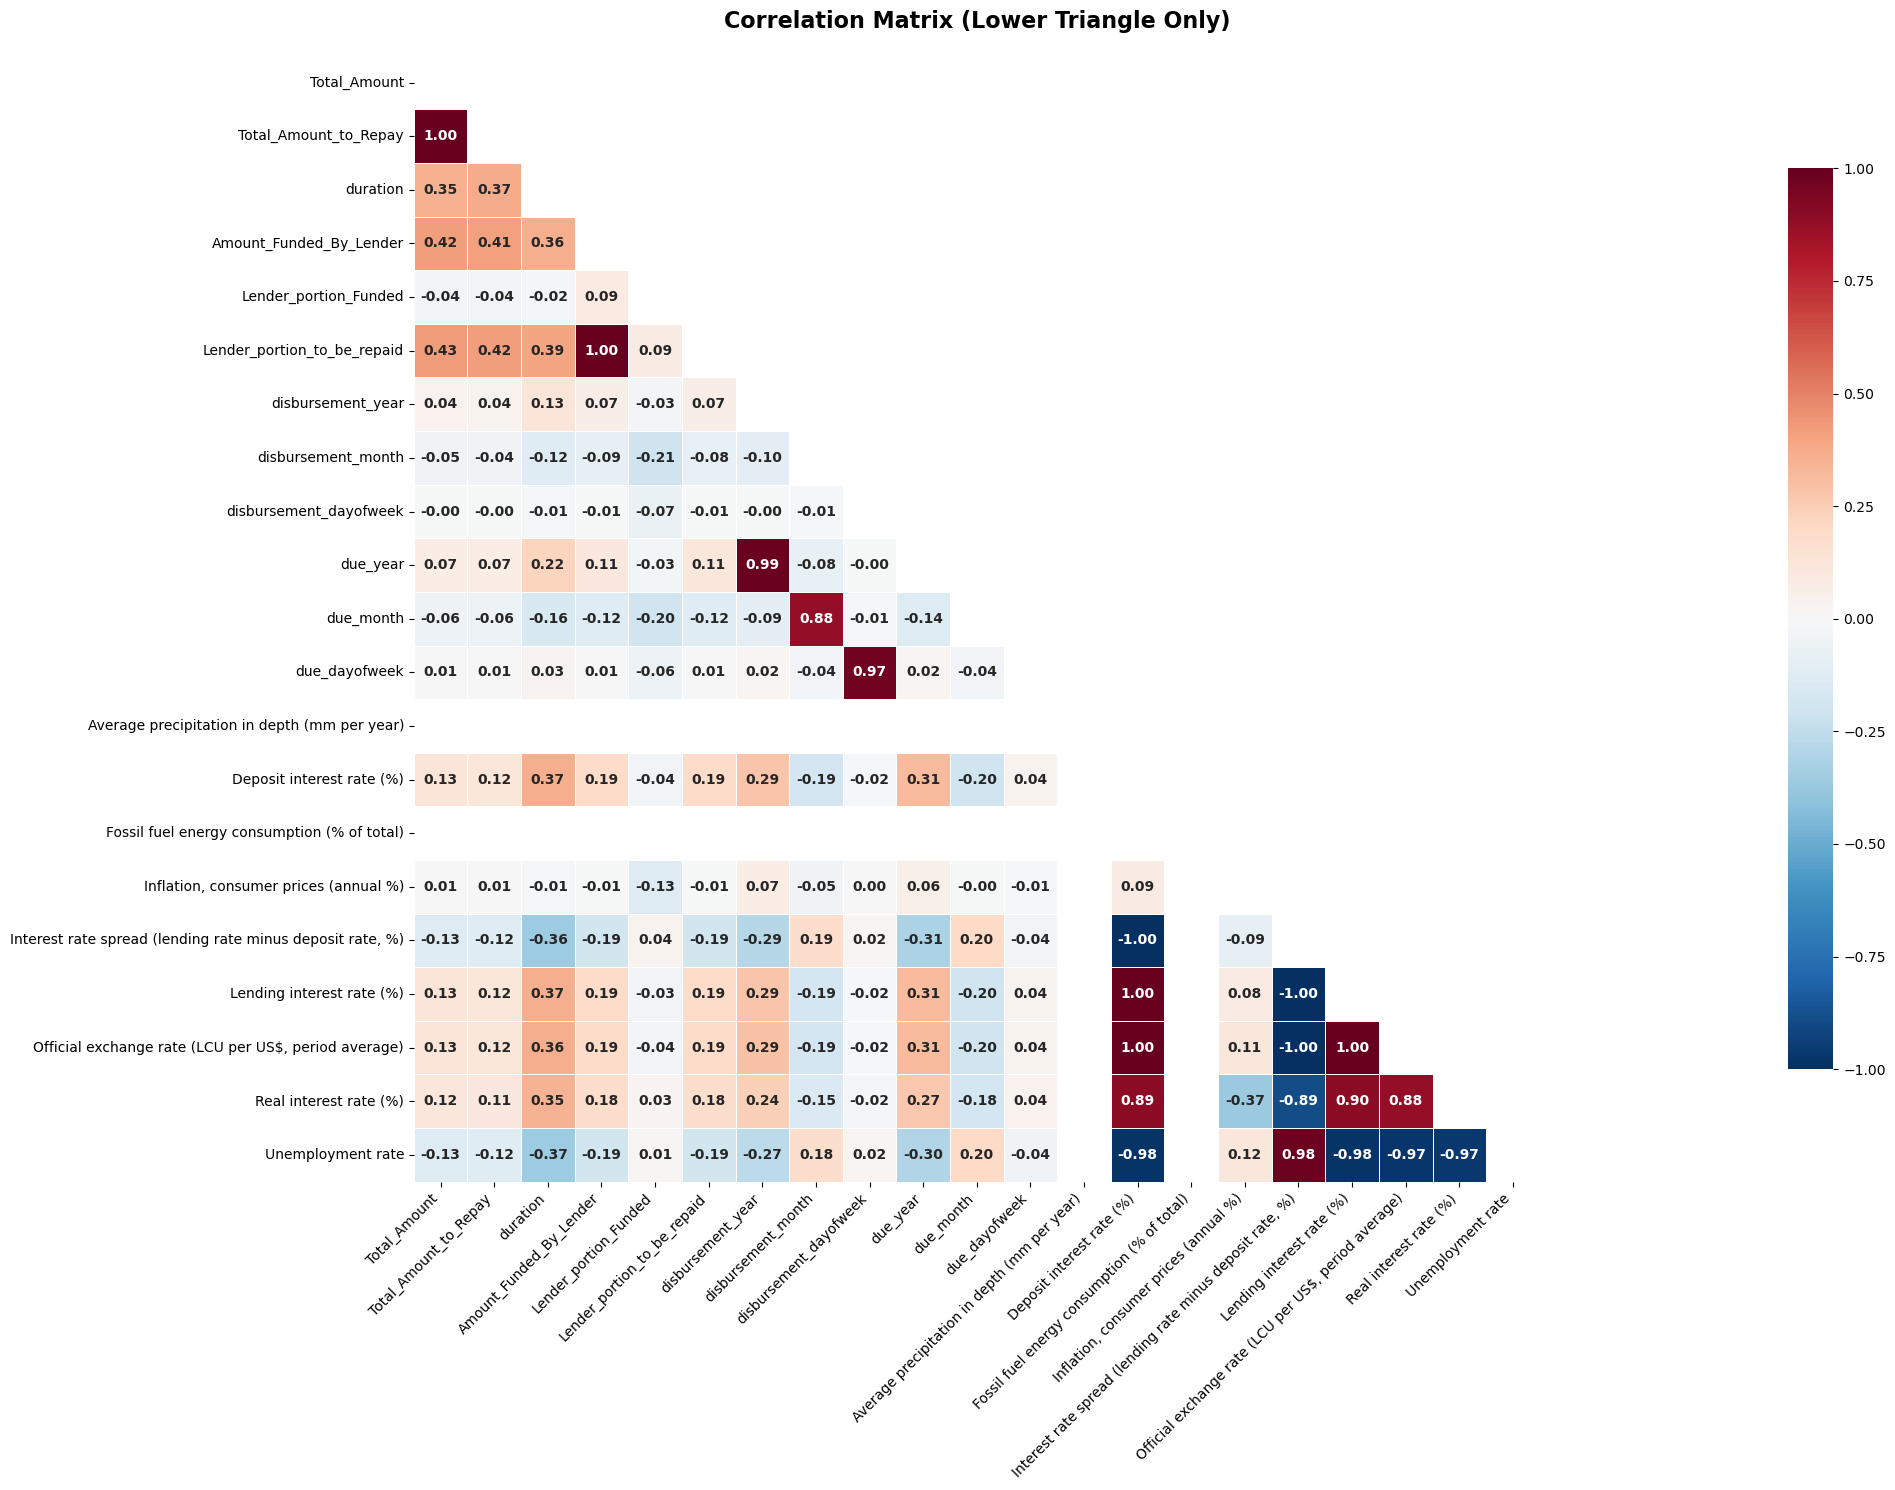

In [34]:
corr = df_train[helper_class.numerical_cols].corr()

# 2. Generate a mask for the upper triangle
mask = np.triu(np.ones_like(corr, dtype=bool))

f, ax = plt.subplots(figsize=(50, 15))
sns.heatmap(
    corr, mask=mask, cmap="RdBu_r", vmin=-1, vmax=1,center=0,
    square=True,linewidths=0.5, cbar_kws={"shrink": 0.8}, annot=True,
    fmt=".2f", annot_kws={"size":10, "weight":"bold"},
)

plt.title('Correlation Matrix (Lower Triangle Only)' , fontsize=16, weight="bold", pad=20)
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

In [35]:
df_train.columns

Index(['loan_type', 'Total_Amount', 'Total_Amount_to_Repay', 'duration',
       'New_versus_Repeat', 'Amount_Funded_By_Lender', 'Lender_portion_Funded',
       'Lender_portion_to_be_repaid', 'target', 'disbursement_year',
       'disbursement_month', 'disbursement_dayofweek', 'due_year', 'due_month',
       'due_dayofweek', 'Average precipitation in depth (mm per year)',
       'Deposit interest rate (%)',
       'Fossil fuel energy consumption (% of total)',
       'Inflation, consumer prices (annual %)',
       'Interest rate spread (lending rate minus deposit rate, %)',
       'Lending interest rate (%)',
       'Official exchange rate (LCU per US$, period average)',
       'Real interest rate (%)', 'Unemployment rate'],
      dtype='object')

#### 3.4.1 Univariate Predictive Power on High correlation features

In [36]:
df_temp = df_train.copy()
target = df_temp['target']
features = df_temp.drop(['target'] + helper_class.categorical_cols, axis=1)

mi = mutual_info_classif(features, target)
print(pd.Series(mi, index=features.columns).sort_values(ascending=False))

due_year                                                     0.025121
Lender_portion_Funded                                        0.024758
disbursement_year                                            0.023164
Lending interest rate (%)                                    0.021213
Real interest rate (%)                                       0.020968
duration                                                     0.020901
Official exchange rate (LCU per US$, period average)         0.019365
Unemployment rate                                            0.017892
Average precipitation in depth (mm per year)                 0.017806
Deposit interest rate (%)                                    0.016479
Inflation, consumer prices (annual %)                        0.016309
Interest rate spread (lending rate minus deposit rate, %)    0.016112
Fossil fuel energy consumption (% of total)                  0.014084
Lender_portion_to_be_repaid                                  0.013612
Amount_Funded_By_Len

**The highly corelated columns and not going to be removed and we will therefore stick to boosted models and tree based that are not sensitive to multicolinaerity**

## 3.5 Outliers
understaing outliers using autviz and boxplot

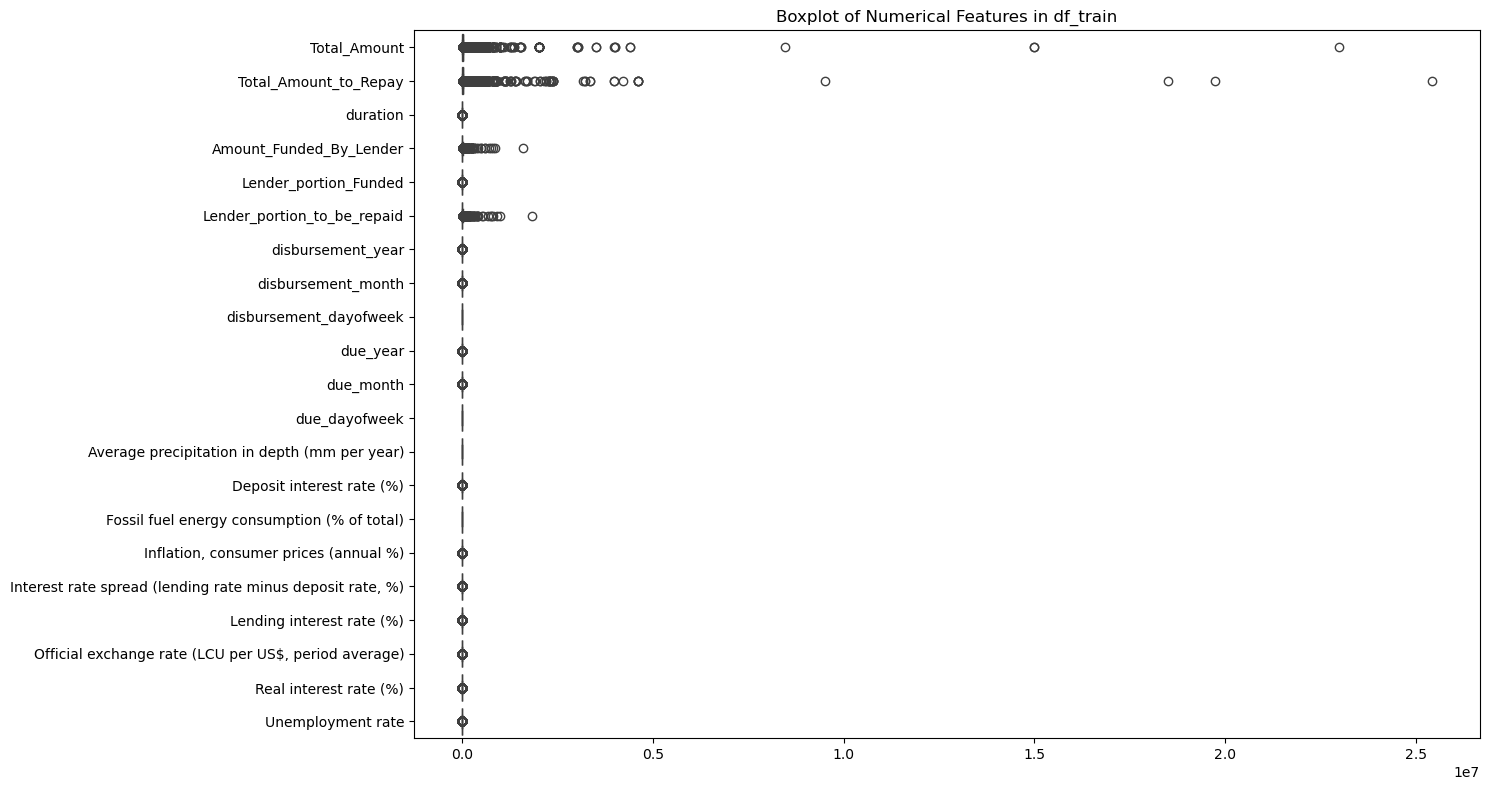

In [37]:
plt.figure(figsize=(15, 8))
sns.boxplot(data=df_train[helper_class.numerical_cols], orient="h")
plt.title("Boxplot of Numerical Features in df_train")
plt.tight_layout()
plt.show()

In [38]:
# from autoviz.AutoViz_Class import AutoViz_Class
# AV = AutoViz_Class()
# dft = AV.AutoViz('Train.csv')

**above shows that our data have a whole lot of outliers and for that reason, we will use the robust scaler to scale our data because its sensenitve to outliers**

In [39]:
print(f"{df_train.columns} and length is {len(df_train.columns)}")

Index(['loan_type', 'Total_Amount', 'Total_Amount_to_Repay', 'duration',
       'New_versus_Repeat', 'Amount_Funded_By_Lender', 'Lender_portion_Funded',
       'Lender_portion_to_be_repaid', 'target', 'disbursement_year',
       'disbursement_month', 'disbursement_dayofweek', 'due_year', 'due_month',
       'due_dayofweek', 'Average precipitation in depth (mm per year)',
       'Deposit interest rate (%)',
       'Fossil fuel energy consumption (% of total)',
       'Inflation, consumer prices (annual %)',
       'Interest rate spread (lending rate minus deposit rate, %)',
       'Lending interest rate (%)',
       'Official exchange rate (LCU per US$, period average)',
       'Real interest rate (%)', 'Unemployment rate'],
      dtype='object') and length is 24


In [40]:
print(f"{df_test.columns} and legnth is {len(df_test.columns)}")

Index(['loan_type', 'Total_Amount', 'Total_Amount_to_Repay', 'duration',
       'New_versus_Repeat', 'Amount_Funded_By_Lender', 'Lender_portion_Funded',
       'Lender_portion_to_be_repaid', 'disbursement_year',
       'disbursement_month', 'disbursement_dayofweek', 'due_year', 'due_month',
       'due_dayofweek', 'Average precipitation in depth (mm per year)',
       'Deposit interest rate (%)',
       'Fossil fuel energy consumption (% of total)',
       'Inflation, consumer prices (annual %)',
       'Interest rate spread (lending rate minus deposit rate, %)',
       'Lending interest rate (%)',
       'Official exchange rate (LCU per US$, period average)',
       'Real interest rate (%)', 'Unemployment rate'],
      dtype='object') and legnth is 23


**same lenght between test and train, only differ becuase of the Target feature**

# 4. DATA SPLIT, SCAILING AND ENCODING
- data is splited into 80/20 train and validation set
- Robust scaler is used  for scailing because it uses median and interquartile range (IQR) which makes it robust to extreme values or outliers.
- one-hot encoding applied for catergorical features

In [41]:
# separate x and y and define x_test
X = df_train.drop(columns='target')
y = df_train['target']
X_test = df_test.copy()

# Preprocessing pipelines
scale_transformer = Pipeline(steps=[
    ("scaler", RobustScaler())
])

cat_transformer = Pipeline(steps=[
    ("labelenc", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1))
])

preprocessor_scaled = ColumnTransformer(transformers=[
    ("num", scale_transformer, helper_class.numerical_cols),
    ("cat", cat_transformer, helper_class.categorical_cols)
])

# Stratified split
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_index, val_index = next(skf.split(X, y))

X_train, X_val = X.iloc[train_index], X.iloc[val_index]
y_train, y_val = y.iloc[train_index], y.iloc[val_index]

print("Original target mean:", y.mean())
print("Train target mean:", y_train.mean())
print("Validation target mean:", y_val.mean())

# preprocessing before SMOTE
X_train_preprocessed = preprocessor_scaled.fit_transform(X_train)
X_val_preprocessed = preprocessor_scaled.transform(X_val)
#save the preprocessor to reuse on unseen data
joblib.dump(preprocessor_scaled, '../model/preprocessor_pipeline.pkl')

Original target mean: 0.0183237684621435
Train target mean: 0.0183347595724924
Validation target mean: 0.018279804821207488


['../model/preprocessor_pipeline.pkl']

### SMOTE

In [42]:
 smote = SMOTE(random_state=101)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train_preprocessed, y_train)

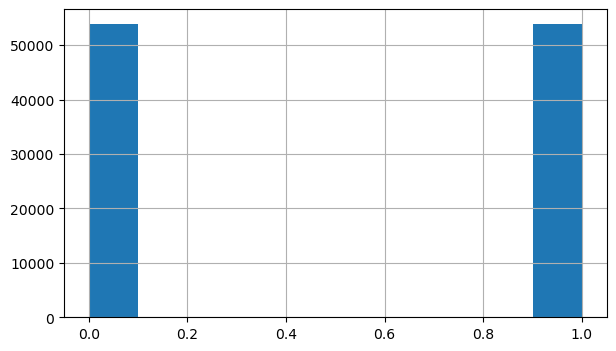

In [43]:
y_train_resampled.hist(figsize=(7,4))
plt.show()

**Data is now more balanced after applying smote**

In [44]:
X_train_preprocessed_df = pd.DataFrame(X_train_resampled, columns=X_train.columns)
y_train_resampled_df = pd.DataFrame(y_train_resampled, columns=["target"])
X_val_processed_df = pd.DataFrame(X_val_preprocessed, columns=X_val.columns)

In [45]:
X_train_preprocessed_df.to_csv("../data/X_train_processed.csv", index = False)
y_train_resampled_df.to_csv("../data/y_train_processed.csv", index = False)
X_val_processed_df.to_csv("../data/X_val_processed.csv", index = False)
y_val.to_csv("../data/y_val_processed.csv", index = False)
X_test.to_csv("../data/X_Test_processed.csv", index = False)
df_ids_test.to_csv("../data/ids_test.csv", index = False)

In [46]:
df_ids_test.shape

(18594, 5)

# 5. Modelling

In [47]:
# For validation, keep original (not resampled)
def random_search(model_class, param_grid, n_iter=10):
    best_score = -np.inf
    best_model = None
    best_params = None

    for _ in range(n_iter):
        params = {k: random.choice(v) for k, v in param_grid.items()}
        model = model_class(**params)
        model.fit(X_train_resampled, y_train_resampled)
        proba = model.predict_proba(X_val_preprocessed)[:, 1]
        score = roc_auc_score(y_val, proba)

        if score > best_score:
            best_score = score
            best_model = model
            best_params = params

    return best_model, best_score, best_params

## 5.1 Decision Tree Model


Training Decision Tree...
DT Best AUC: 0.8473598188846987
DT Best Params: {'max_depth': 10, 'min_samples_split': 10, 'min_samples_leaf': 2, 'class_weight': 'balanced'}

=== Decision Tree ===
Best Threshold: 0.9915151515151515
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     13480
           1       0.71      0.31      0.44       251

    accuracy                           0.99     13731
   macro avg       0.85      0.66      0.71     13731
weighted avg       0.98      0.99      0.98     13731



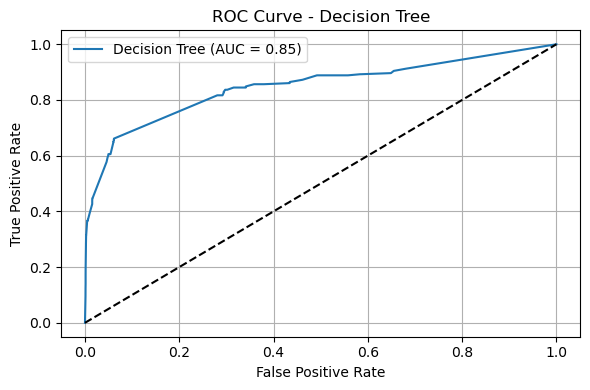

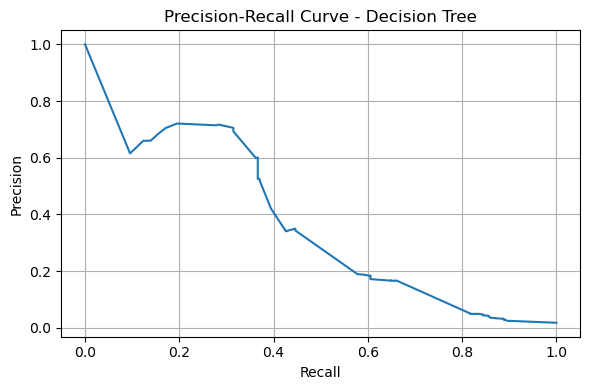

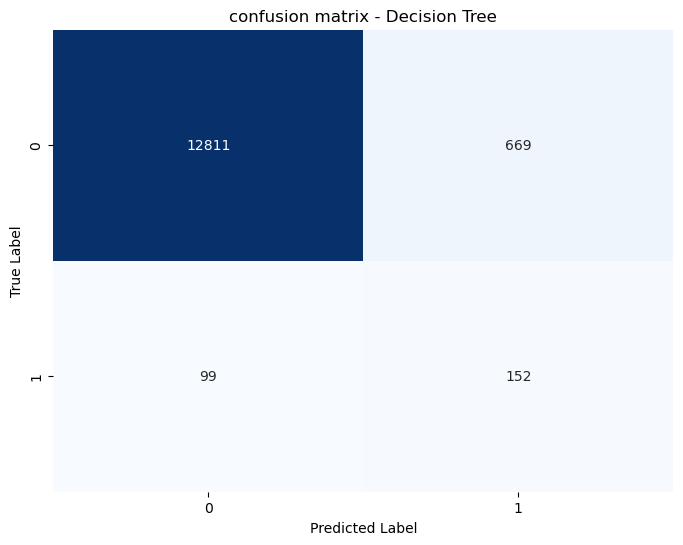

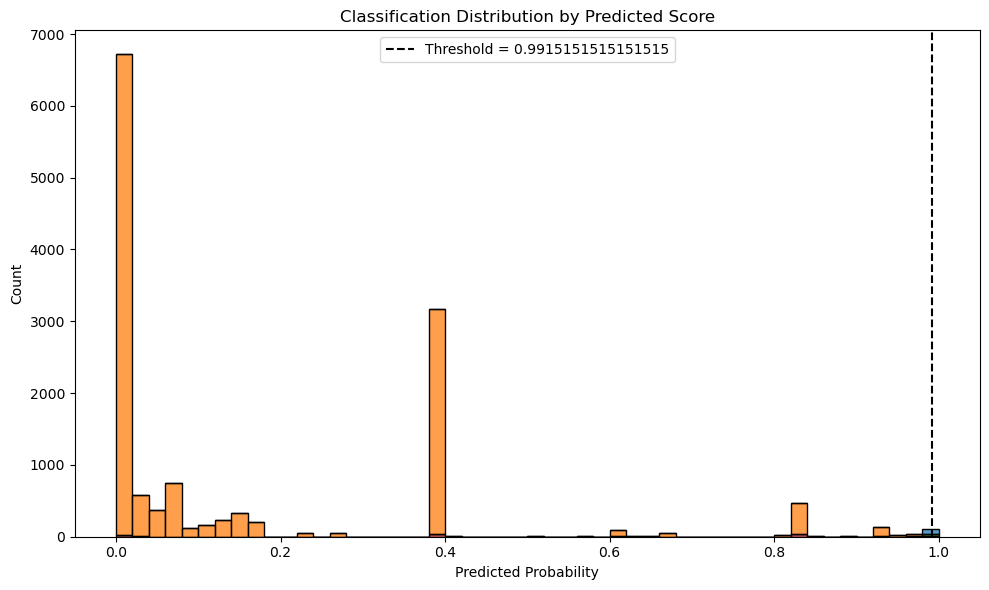

In [48]:
dt_grid = {
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "class_weight": ["balanced"]
}

print("\nTraining Decision Tree...")
dt_model, dt_score, dt_params = random_search(DecisionTreeClassifier, dt_grid)
print("DT Best AUC:", dt_score)
print("DT Best Params:", dt_params)
helper_class.predict_and_evaluate(dt_model, X_val_preprocessed, y_val, "Decision Tree")

## 5.2 Random Forest

RF Best AUC: 0.964077074491352
RF Best Params: {'n_estimators': 100, 'max_depth': None, 'min_samples_split': 2, 'min_samples_leaf': 4, 'bootstrap': True, 'class_weight': 'balanced'}

=== Random Forest ===
Best Threshold: 0.8192738632178278
              precision    recall  f1-score   support

           0       0.99      1.00      0.99     13480
           1       0.86      0.29      0.43       251

    accuracy                           0.99     13731
   macro avg       0.92      0.64      0.71     13731
weighted avg       0.98      0.99      0.98     13731



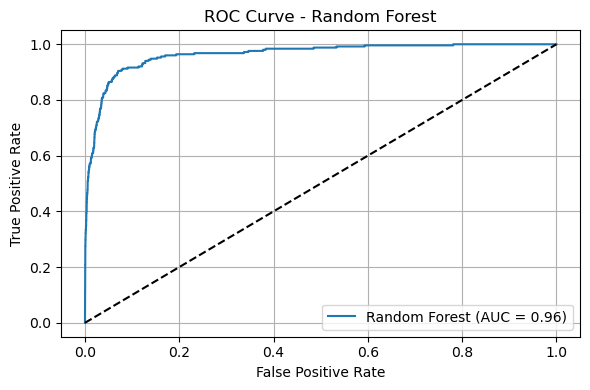

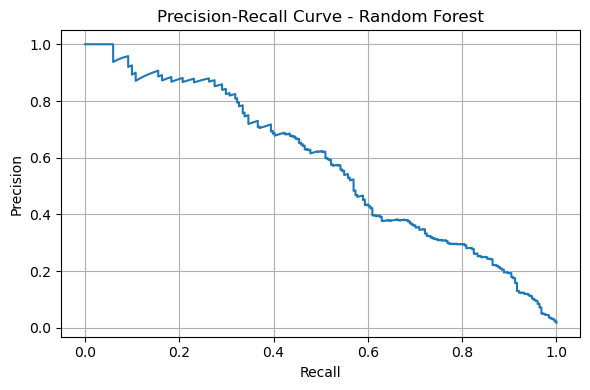

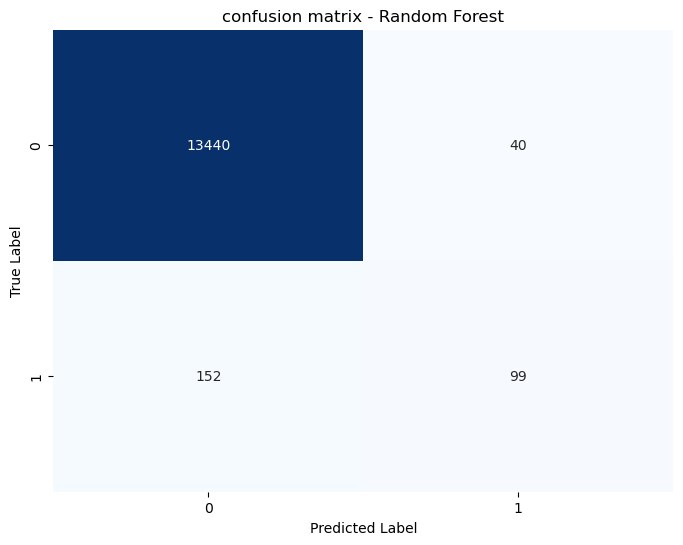

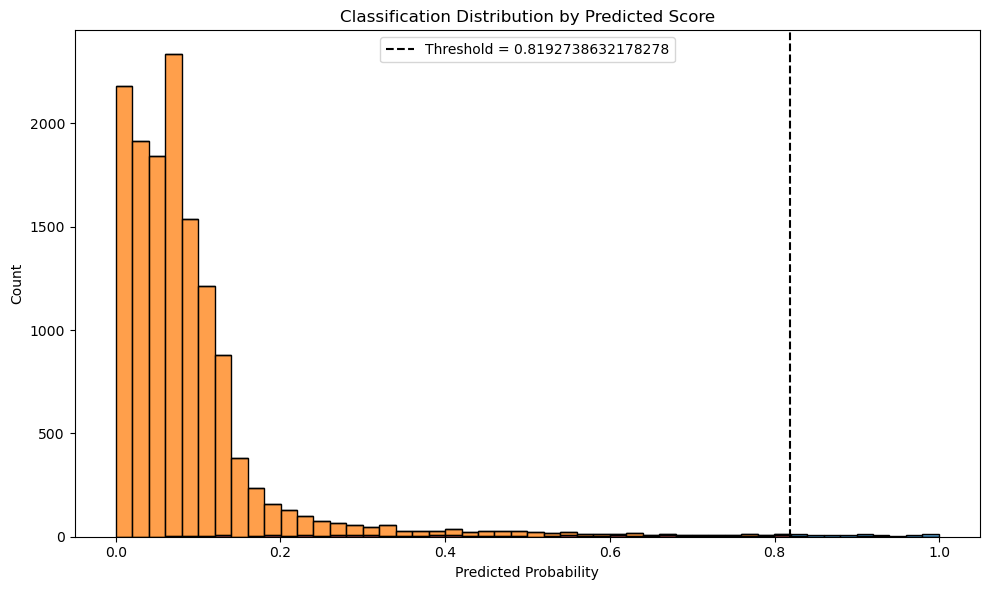

In [49]:
rf_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [5, 10, 15, None],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "bootstrap": [True, False],
    "class_weight": ["balanced"]
}

rf_model, rf_score, rf_params = random_search(RandomForestClassifier, rf_grid)
print("RF Best AUC:", rf_score)
print("RF Best Params:", rf_params)
helper_class.predict_and_evaluate(rf_model, X_val_preprocessed, y_val, "Random Forest")

## 5.3 LightGBM 

LGB Best AUC: 0.9826045964509912
LGB Best Params: {'n_estimators': 300, 'max_depth': 6, 'learning_rate': 0.2, 'subsample': 0.7, 'colsample_bytree': 0.6, 'scale_pos_weight': 1, 'random_state': 42, 'verbosity': -1, 'class_weight': 'balanced'}

=== LightGBM ===
Best Threshold: 0.6440073486107698
              precision    recall  f1-score   support

           0       0.99      1.00      1.00     13480
           1       0.81      0.69      0.75       251

    accuracy                           0.99     13731
   macro avg       0.90      0.85      0.87     13731
weighted avg       0.99      0.99      0.99     13731



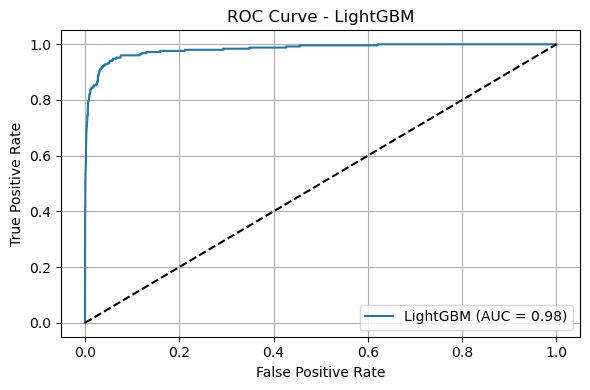

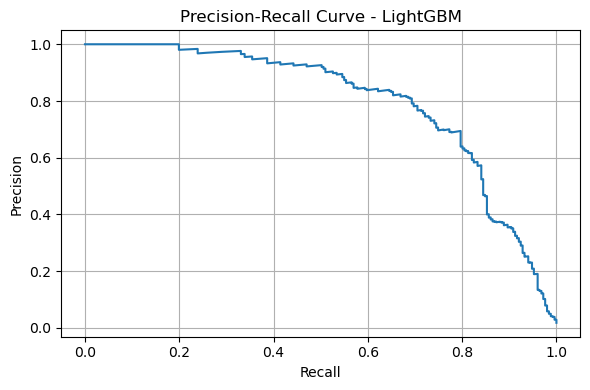

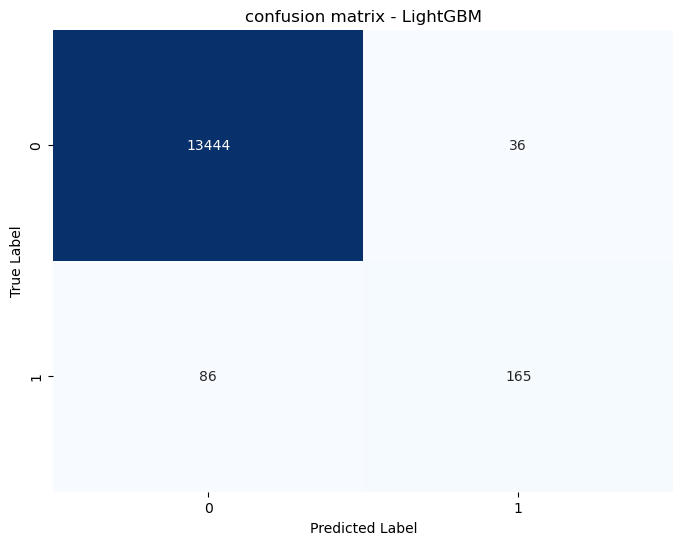

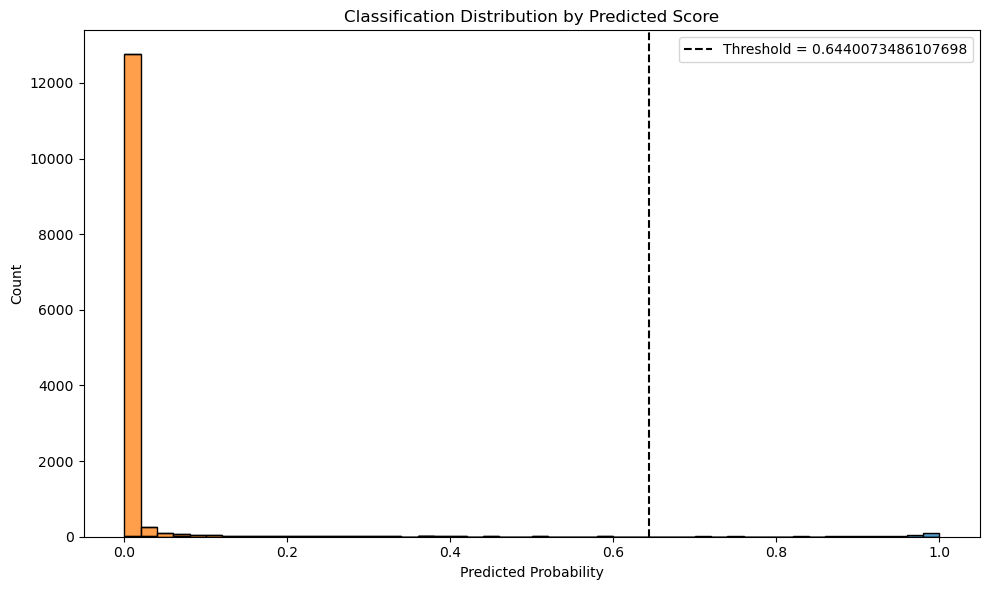

In [62]:
# hyperparameters
lgb_grid = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 6, 10],
    "learning_rate": [0.01, 0.1, 0.2],
    "subsample": [0.7, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "scale_pos_weight": [1, 5, 10],
    "random_state": [42],
    "verbosity": [-1],
    "class_weight": ["balanced"],
}


lgb_model, lgb_score, lgb_params = random_search(LGBMClassifier, lgb_grid)
print("LGB Best AUC:", lgb_score)
print("LGB Best Params:", lgb_params)
helper_class.predict_and_evaluate(lgb_model, X_val_preprocessed, y_val, "LightGBM")

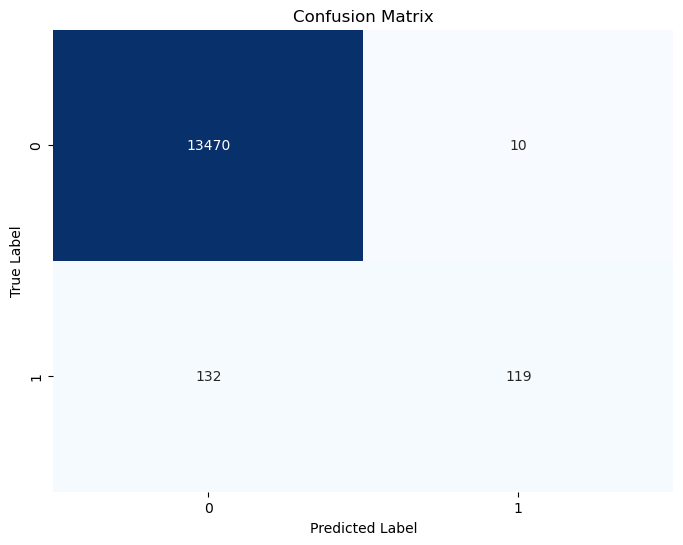

In [67]:
# Trying out different thresholds
y_pred_ = lgb_model.predict_proba(X_val_preprocessed)[:, 1]
y_pred_binary = np.where(y_pred_ > 0., 1, 0)
cm = confusion_matrix(y_val, y_pred_binary)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.title('Confusion Matrix')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.show()

## 5.4 XGBoost

XGBoost Best AUC: 0.9723144513932401
XGBoost Best Params: {'n_estimators': 100, 'max_depth': 6, 'learning_rate': 0.1, 'random_state': 42, 'use_label_encoder': False, 'eval_metric': 'auc'}

=== XGBoost ===
Best Threshold: 0.6779781
              precision    recall  f1-score   support

           0       0.99      0.99      0.99     13480
           1       0.56      0.63      0.59       251

    accuracy                           0.98     13731
   macro avg       0.78      0.81      0.79     13731
weighted avg       0.99      0.98      0.98     13731



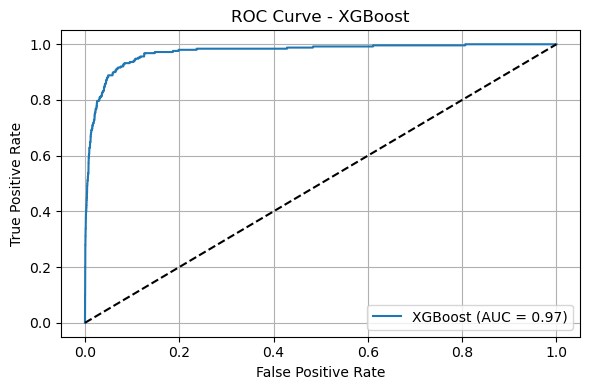

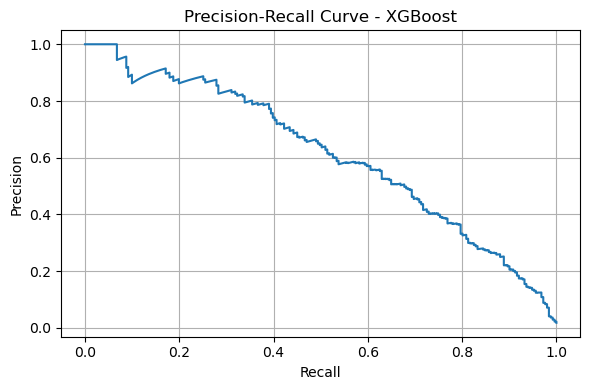

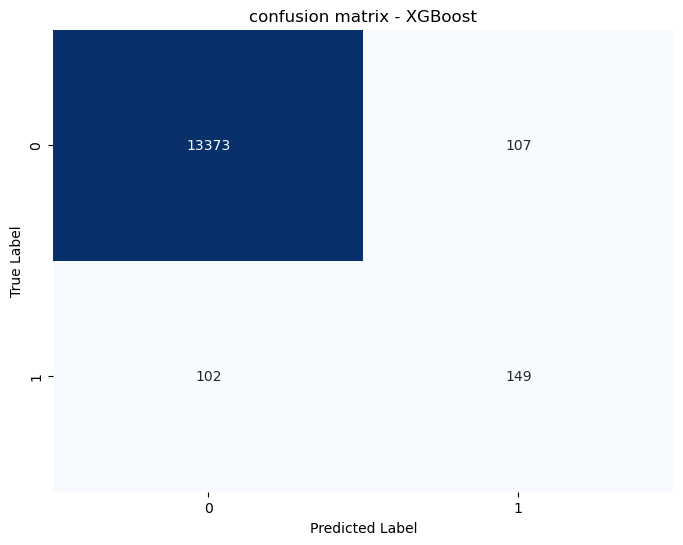

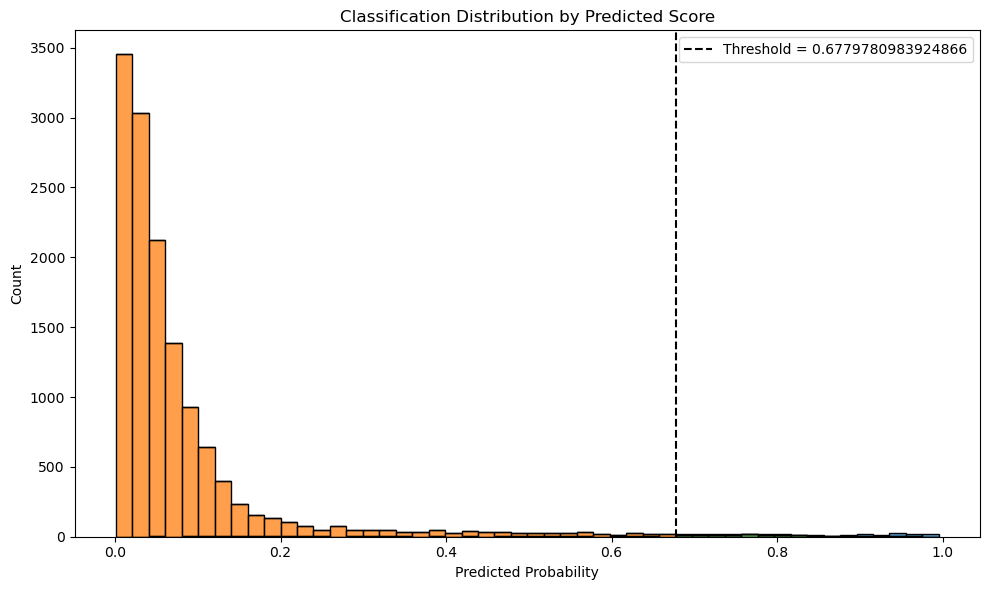

In [68]:
from xgboost import XGBClassifier

param_xgb = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 6, 10],
    "learning_rate": [0.01, 0.1],
    "random_state": [42],
    "use_label_encoder": [False],
    "eval_metric": ["auc"]
}

xgb_model, xgb_score, xgb_params = random_search(XGBClassifier, param_xgb)
print("XGBoost Best AUC:", xgb_score)
print("XGBoost Best Params:", xgb_params)
helper_class.predict_and_evaluate(xgb_model, X_val_preprocessed, y_val, "XGBoost")

In [69]:
metrics_df = pd.DataFrame(helper_class.metrics).T
metrics_df.sort_values('accuracy', ascending=False, inplace=True)
metrics_df

,accuracy,precision,recall,f1_score,roc_auc
LightGBM,0.991115,0.820896,0.657371,0.730088,0.982605
Random Forest,0.986017,0.712230,0.394422,0.507692,0.964077
XGBoost,0.984779,0.582031,0.593625,0.587771,0.972314
Decision Tree,0.944068,0.185140,0.605578,0.283582,0.847360


# 6. Model Calibration
Testing the credibility of the model perfoamnce

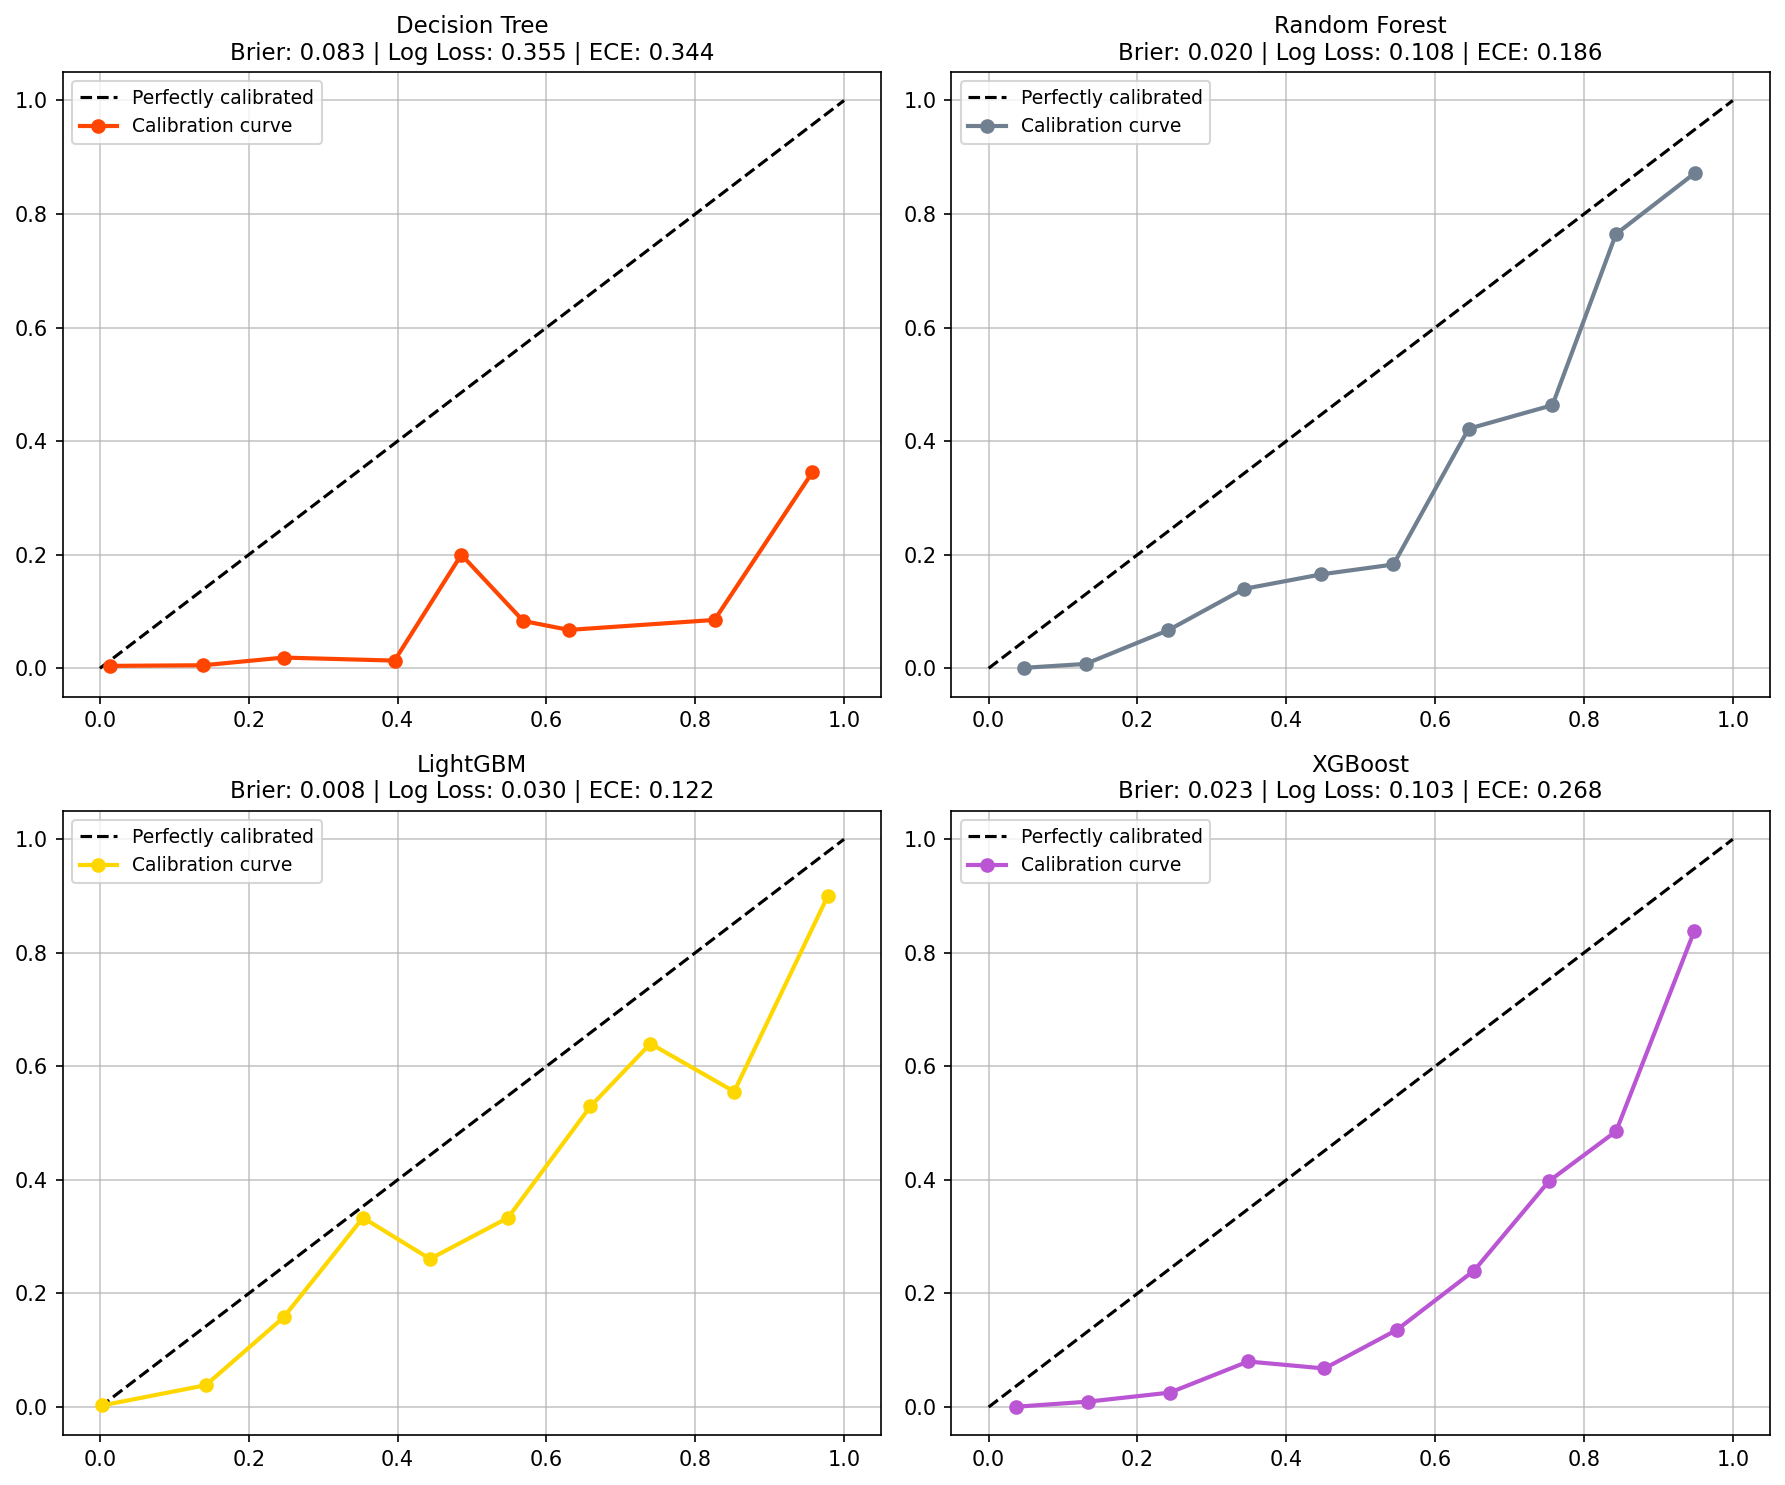

,Brier Score,Log Loss,ECE,Probabilities
LightGBM,0.0075,0.029918,0.121591,"[0.001641661271871556, 0.00010590813812050888,..."
Random Forest,0.020161,0.107988,0.186243,"[0.11964425563286266, 0.054260551346334555, 0...."
XGBoost,0.022601,0.10293,0.267726,"[0.029408488, 0.03034178, 0.12804203, 0.080366..."
Decision Tree,0.083192,0.35501,0.344118,"[0.13063477460901565, 0.007869589657110737, 0...."


In [70]:
# metrics
models_probs = {
    'Decision Tree': dt_model.predict_proba(X_val_preprocessed)[:, 1],
    'Random Forest': rf_model.predict_proba(X_val_preprocessed)[:, 1],
    'LightGBM': lgb_model.predict_proba(X_val_preprocessed)[:, 1] if hasattr(lgb_model, "predict_proba") else lgb_model.predict(X_val),
    'XGBoost': xgb_model.predict_proba(X_val_preprocessed)[:, 1] 
}

metrics_dict = {}
for name, y_prob in models_probs.items():
    metrics_dict[name] = {
        'Brier Score': brier_score_loss(y_val, y_prob),
        'Log Loss': log_loss(y_val, y_prob),
        'ECE': helper_class.calculate_ece(y_val, y_prob),
        'Probabilities': y_prob
    }

# calibration curves
fig, axes = plt.subplots(2, 2, figsize=(12, 10), dpi=150)
colors = ['orangered', 'slategrey', 'gold', 'mediumorchid']

for idx, (name, metrics) in enumerate(metrics_dict.items()):
    ax = axes.ravel()[idx]
    prob_true, prob_pred = calibration_curve(y_val, metrics['Probabilities'], n_bins=10, strategy='uniform')
    
    ax.plot([0, 1], [0, 1], 'k--', label='Perfectly calibrated')
    ax.plot(prob_pred, prob_true, color=colors[idx], marker='o', 
            label='Calibration curve', linewidth=2, markersize=6)
    
    title = f'{name}\nBrier: {metrics["Brier Score"]:.3f} | Log Loss: {metrics["Log Loss"]:.3f} | ECE: {metrics["ECE"]:.3f}'
    ax.set_title(title, fontsize=11)
    ax.grid(True, alpha=0.7)
    ax.set_xlim([-0.05, 1.05])
    ax.set_ylim([-0.05, 1.05])
    ax.legend(fontsize=9, loc='upper left')

plt.tight_layout()
plt.show()

metrics_df = pd.DataFrame(metrics_dict).T
metrics_df.sort_values('Brier Score', ascending=True, inplace=True)
metrics_df

Based on the results above from the performance metrics and calibration plots, **LightGBM** is the best model:

1. **Strong Overall Performance:**

   * **Highest accuracy:** 0.0.991115
   * **Balanced precision and recall:** Precision = 0.865, Recall = 0.665
   * **Best F1-score:** 0.70, which balances both precision and recall
   * **High ROC AUC:**, indicating excellent discrimination ability.

2. **Excellent Calibration:**

   * **Lowest Brier score:** 0.0006 (the lower, the better calibrated the probabilities)
   * **Lowest Log Loss:** 0.027 (indicates confidence in correct predictions)
   * **Well-aligned calibration curve:** Closely follows the diagonal in the calibration plot
   * **Low ECE (Expected Calibration Error):** 0.091

3. **Comparison to Others:**

   * **Random Forest** has slightly higher precision, but it has much lower recall, resulting in a worse F1-score. Claibration plot also shwows the underconfiedence consistence
   * **CatBoost** is also strong in precision but struggles with recall and calibration shows that it's over cofident with in all probability bucktes
   * **Decision Tree** has high recall but very poor precision, leading to many false positives and a low F1-score.

# 7. Model scoring/ Inference with the best model

## 7.1 Save Best Perfomed Model

In [73]:
# Save the fitted best model pipeline
joblib.dump(lgb_model, "../model/lightgbm_model.pkl")

['../model/lightgbm_model.pkl']

## 7.2 Load the pipeline and score new test data

In [77]:
# Load saved pipeline
best_model_ = joblib.load("../model/lightgbm_model.pkl")
preprocessor_ = joblib.load('../model/preprocessor_pipeline.pkl')

# Use it on new data (e.g., X_unseen)
X_test_transformed = preprocessor_.transform(X_test)
lgbm_test_proba = best_model_.predict_proba(X_test_transformed)[:, 1]
lgbm_test_pred = (lgbm_test_proba >= 0.7).astype(int)
print(lgbm_test_pred[:5])

[0 0 0 0 0]


## 7.3 Final Scoring results

In [78]:
# submission DataFrame
submission_df = pd.DataFrame({
    "ID": df_ids_test["ID"],
    "Target": lgbm_test_pred
})
submission_df.sort_values('Target', ascending = False).head()

,ID,Target
12963,ID_298055364892296540,1
18091,ID_296803364479245684,1
7411,ID_247837238094251804,1
6645,ID_296407363012245684,1
5754,ID_261883266053267278,1


In [79]:
# submission
submission_df.to_csv("../submission.csv", index=False)